# Clustering basado en prototipos con la base de datos Iris

En este cuaderno trabajaremos el **clustering basado en prototipos** usando el dataset clásico **Iris**.

Objetivos:

- Recordar la estructura del conjunto de datos Iris.
- Aplicar **k-means** como ejemplo de clustering basado en prototipos.
- Explorar cómo elegir el número de clusters (método del codo, silhouette).
- Visualizar los clusters en el espacio de características y en una proyección 2D (PCA).
- Comparar los clusters obtenidos con las clases reales (solo para evaluación, no para entrenar).
- Plantear una **tarea final** para profundizar.

## Índice

1. Importación de librerías  
2. Carga y exploración del dataset Iris  
3. Preprocesado ligero y PCA a 2D (para visualización)  
4. Clustering con k-means (k=3)  
5. Evaluación del clustering (cuando sí conocemos las etiquetas reales)  
6. Selección del número de clusters  
   - Método del codo (elbow)  
   - Silhouette score  
7. Visualización de los clusters  
8. Tarea final

## 1. Importación de librerías

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    adjusted_rand_score,
    homogeneity_score,
    completeness_score,
    v_measure_score
)

# Configuración de gráficos
plt.rcParams['figure.figsize'] = (6, 4)
plt.rcParams['axes.grid'] = True

## 2. Carga y exploración del dataset Iris

Cargamos el dataset **[Iris](https://archive.ics.uci.edu/dataset/53/iris)** desde `scikit-learn` y lo exploramos rápidamente.

- 150 muestras
- 4 características:
  - sepal length (cm)
  - sepal width (cm)
  - petal length (cm)
  - petal width (cm)
- 3 clases:
  - setosa
  - versicolor
  - virginica

En clustering **no usamos las etiquetas para entrenar**, solo para evaluar al final.

In [2]:
iris = load_iris()

X = iris.data            # características
y = iris.target          # etiquetas verdaderas (solo para evaluar después)
feature_names = iris.feature_names
target_names = iris.target_names

df = pd.DataFrame(X, columns=feature_names)
df['target'] = y
df['target_name'] = df['target'].apply(lambda i: target_names[i])

df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,target_name
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


### 2.1 Información básica

In [3]:
print("Shape de X:", X.shape)
print("Shape de y:", y.shape)
print("Características:", feature_names)
print("Clases:", target_names)

print("\nDistribución de clases reales:")
print(df['target_name'].value_counts())

Shape de X: (150, 4)
Shape de y: (150,)
Características: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Clases: ['setosa' 'versicolor' 'virginica']

Distribución de clases reales:
target_name
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


### 2.2 Histogramas de características

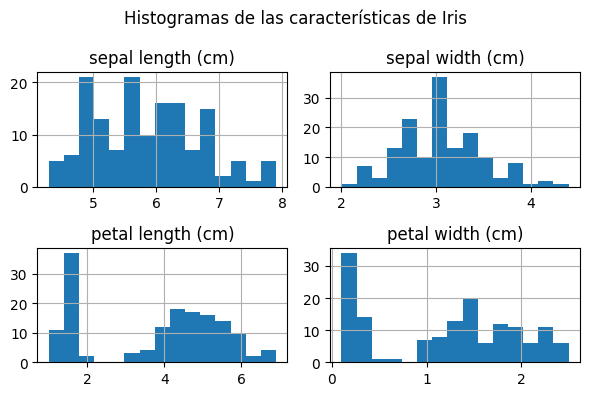

In [4]:
df[feature_names].hist(bins=15)
plt.suptitle("Histogramas de las características de Iris")
plt.tight_layout()
plt.show()

### 2.3 Diagramas de dispersión simples

Representamos **petal length vs petal width**, coloreando por la clase real, para ver
si hay separación natural entre las especies.

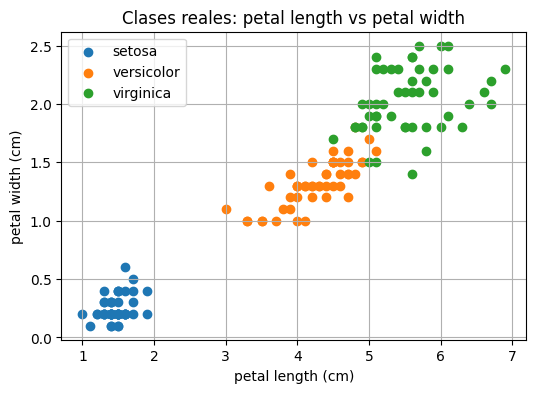

In [5]:
x_feat = 'petal length (cm)'
y_feat = 'petal width (cm)'

for i, name in enumerate(target_names):
    subset = df[df['target_name'] == name]
    plt.scatter(subset[x_feat], subset[y_feat], label=name)

plt.xlabel(x_feat)
plt.ylabel(y_feat)
plt.title("Clases reales: petal length vs petal width")
plt.legend()
plt.show()

## 3. Preprocesado ligero y PCA a 2D (para visualización)

Aunque **k-means no exige estrictamente escalado**, es muy recomendable cuando:

- Las características tienen escalas diferentes.
- Queremos que ninguna característica "domine" la distancia Euclídea.

Aquí:

1. Aplicamos `StandardScaler` para tener media 0 y desviación típica 1.
2. Aplicamos **PCA** para proyectar a 2 dimensiones (solo para visualización; el clustering principal
   lo haremos tanto en el espacio original como en el reducido).

In [6]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print("Shape original:", X.shape)
print("Shape tras PCA a 2D:", X_pca.shape)

components_df = pd.DataFrame(
    pca.components_,
    columns=feature_names,
    index=["PC1", "PC2"]
)

print(components_df)

Shape original: (150, 4)
Shape tras PCA a 2D: (150, 2)
     sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
PC1           0.521066         -0.269347           0.580413          0.564857
PC2           0.377418          0.923296           0.024492          0.066942


Visualizamos las clases reales en la proyección PCA 2D:

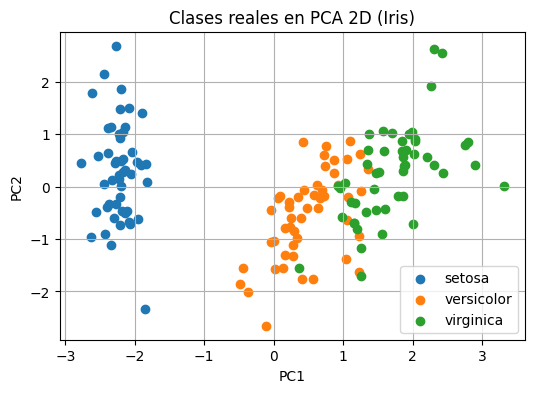

In [7]:
for i, name in enumerate(target_names):
    subset = X_pca[y == i]
    plt.scatter(subset[:, 0], subset[:, 1], label=name)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Clases reales en PCA 2D (Iris)")
plt.legend()
plt.show()

## 4. Clustering con k-means (k=3)

El algoritmo **k-means** es un ejemplo clásico de clustering basado en prototipos:

1. Elegimos un número de clusters \( k \).
2. Inicializamos aleatoriamente \( k \) **centroides** (prototipos).
3. Repetimos:
   - Asignar cada punto al centroide más cercano.
   - Recalcular cada centroide como la media de los puntos asignados.
4. Paramos cuando las asignaciones dejan de cambiar (o el cambio es muy pequeño).

En Iris **sabemos** que hay 3 especies, así que probamos primero con \( k = 3 \).

Usaremos los datos **escalados** para k-means.

In [9]:
k = 3
kmeans = KMeans(
    n_clusters=k,
    random_state=42,
    n_init=10
)

kmeans.fit(X_scaled)
cluster_labels = kmeans.labels_  # etiqueta de cluster asignada a cada punto

print("Etiquetas de cluster (0, 1, 2):")
print(np.unique(cluster_labels, return_counts=True))

Etiquetas de cluster (0, 1, 2):
(array([0, 1, 2], dtype=int32), array([53, 50, 47]))


Visualizamos los centroides en el espacio de características (desescalados):

In [10]:
# Los centroides están en el espacio escalado; los llevamos al espacio original
centroids_scaled = kmeans.cluster_centers_
centroids = scaler.inverse_transform(centroids_scaled)

centroids_df = pd.DataFrame(centroids, columns=feature_names)
centroids_df.index = [f"Cluster {i}" for i in range(k)]
centroids_df

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
Cluster 0,5.801887,2.673585,4.369811,1.413208
Cluster 1,5.006000,3.428000,1.462000,0.246000
Cluster 2,6.780851,3.095745,5.510638,1.972340


También visualizamos los clusters (k-means) en la proyección PCA 2D:

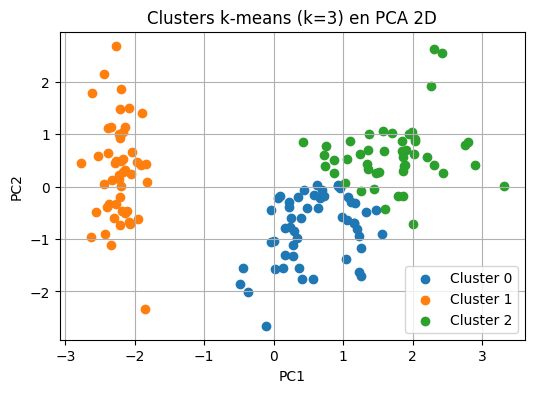

In [11]:
for cluster_id in range(k):
    subset = X_pca[cluster_labels == cluster_id]
    plt.scatter(subset[:, 0], subset[:, 1], label=f"Cluster {cluster_id}")

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Clusters k-means (k=3) en PCA 2D")
plt.legend()
plt.show()

## 5. Evaluación del clustering (usando las clases reales solo para medir)

En clustering **no usamos las etiquetas reales para entrenar**, pero como en este caso sí las tenemos,
podemos compararlas con las etiquetas de cluster para evaluar qué tan bien ha "descubierto" las especies.

Métricas habituales:

- **Adjusted Rand Index (ARI)**: 0 = aleatorio, 1 = perfecto.
- **Homogeneity**: cada cluster contiene principalmente una sola clase.
- **Completeness**: cada clase está principalmente en un solo cluster.
- **V-measure**: media armónica de homogeneity y completeness.

Y también podemos ver la **matriz de confusión** entre clases reales y clusters.

In [12]:
ari = adjusted_rand_score(y, cluster_labels)
h = homogeneity_score(y, cluster_labels)
c = completeness_score(y, cluster_labels)
v = v_measure_score(y, cluster_labels)

print(f"Adjusted Rand Index (ARI): {ari:.4f}")
print(f"Homogeneity:               {h:.4f}")
print(f"Completeness:              {c:.4f}")
print(f"V-measure:                 {v:.4f}")

Adjusted Rand Index (ARI): 0.6201
Homogeneity:               0.6591
Completeness:              0.6598
V-measure:                 0.6595


1. **Adjusted Rand Index (ARI)**: 0.6201
Significa que la coincidencia entre los clusters y las clases reales es bastante buena.

1.0 → clustering perfecto
0.0 → resultado aleatorio
0.62 → los clusters coinciden con las clases reales mucho más que al azar, pero todavía hay bastantes errores.

Los clusters se parecen bastante a las especies reales, pero hay mezclas, especialmente entre versicolor y virginica.

2. **Homogeneity**: 0.6591
Valor medio-alto: los clusters son relativamente “puros”. Es decir, cada cluster contiene sobre todo elementos de una sola clase. Pero no es perfecto
Algunos clusters contienen mezclas de clases.

3. **Completeness**: 0.6598
Cada clase está mayormente agrupada dentro de un solo cluster, pero no al 100%.

Esto mide lo contrario que homogeneity:

homogeneity → un cluster no mezcla clases
completeness → una clase no está dividida en clusters

Una especie concreta puede estar parcialmente repartida entre dos clusters, pero la mayor parte de ella cae en un cluster principal.

### 5.1 Matriz de confusión entre clases reales y clusters

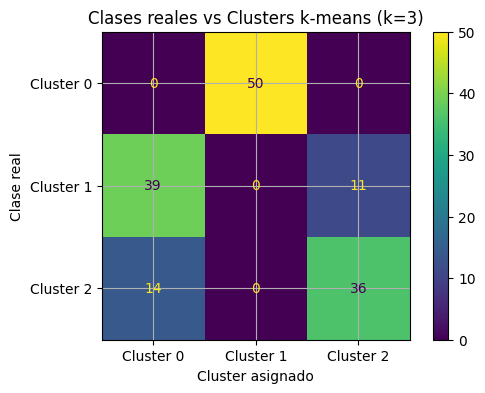

array([[ 0, 50,  0],
       [39,  0, 11],
       [14,  0, 36]])

In [13]:
cm = confusion_matrix(y, cluster_labels)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[f"Cluster {i}" for i in range(k)])
disp.plot()
plt.title("Clases reales vs Clusters k-means (k=3)")
plt.xlabel("Cluster asignado")
plt.ylabel("Clase real")
plt.show()

cm

Observa que:

- Los números de cluster (0, 1, 2) son arbitrarios: no hay correspondencia directa fija con *setosa*, *versicolor*, *virginica*.
- Pero sí podemos ver si cada especie cae mayoritariamente en uno de los clusters.

* Cluster 1. Contiene solo setosa (50). Captura perfectamente la especie setosa
* Cluster 0. Mezcla versicolor (39) y virginica (14). Es un cluster confuso: mezcla dos especies que realmente se parecen mucho
* Cluster 2. Mezcla versicolor (11) y virginica (36). Casi es un cluster “virginica”, pero aún tiene bastante versicolor

## 6. Selección del número de clusters

En problemas reales **no conocemos el número de clusters**.  
Aquí exploramos dos criterios habituales:

1. **Método del codo (elbow)** usando la inercia:
   - La inercia es la suma de las distancias cuadradas de cada punto a su centroide.
   - A medida que aumenta \( k \), la inercia siempre baja, pero buscamos un punto donde deje de bajar “claramente”.
2. **Silhouette score**:
   - Mezcla compactación intra-cluster y separación inter-cluster.
   - Toma valores entre -1 y 1; cuanto más alto, mejor separación.

### 6.1 Método del codo (inercia)

k=1: inercia=600.00
k=2: inercia=222.36
k=3: inercia=139.82
k=4: inercia=114.09
k=5: inercia=90.93
k=6: inercia=81.54
k=7: inercia=72.63
k=8: inercia=62.54
k=9: inercia=55.12
k=10: inercia=47.39


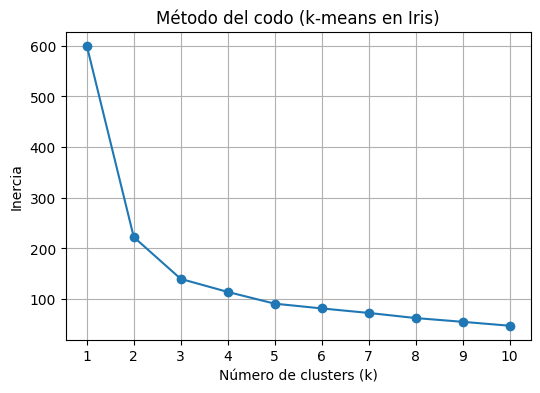

In [14]:
inertias = []
k_values = range(1, 11)

for k in k_values:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    inertias.append(km.inertia_)

for k, inertia in zip(k_values, inertias):
    print(f"k={k}: inercia={inertia:.2f}")

plt.plot(list(k_values), inertias, marker='o')
plt.xlabel("Número de clusters (k)")
plt.ylabel("Inercia")
plt.title("Método del codo (k-means en Iris)")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

### 6.2 Silhouette score para distintos k

k=2: silhouette=0.5818
k=3: silhouette=0.4599
k=4: silhouette=0.3869
k=5: silhouette=0.3459
k=6: silhouette=0.3171
k=7: silhouette=0.3202
k=8: silhouette=0.3387
k=9: silhouette=0.3424
k=10: silhouette=0.3518


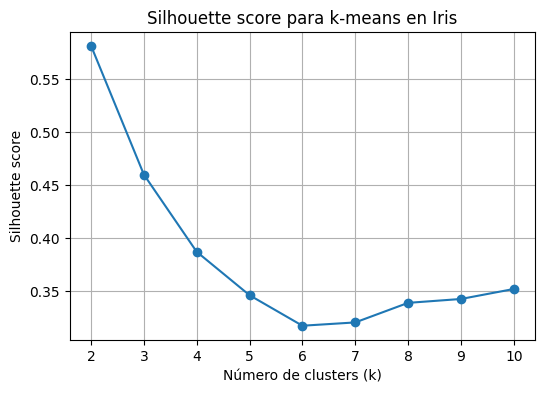

In [15]:
silhouette_scores = []
k_values_sil = range(2, 11)  # silhouette no está definido para k=1

for k in k_values_sil:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels_k = km.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels_k)
    silhouette_scores.append(score)

for k, score in zip(k_values_sil, silhouette_scores):
    print(f"k={k}: silhouette={score:.4f}")

plt.plot(list(k_values_sil), silhouette_scores, marker='o')
plt.xlabel("Número de clusters (k)")
plt.ylabel("Silhouette score")
plt.title("Silhouette score para k-means en Iris")
plt.xticks(list(k_values_sil))
plt.grid(True)
plt.show()

**Comentario rápido:**

- Si el máximo de silhouette está en \( k=2 \), indica que, según esta métrica,
  la mejor separación es en 2 clusters, a pesar de que sepamos que biológicamente hay 3 especies.
- Esto abre la puerta a debatir:
  - ¿Qué está "viendo" k-means en los datos?
  - ¿Son las especies realmente equiesféricas y separables en torno a centroides?

## 7. Visualización de los clusters

Volvemos al caso \( k = 3 \) y comparamos visualmente:

- Clases reales vs clusters.
- Usaremos:
  - Petal length vs petal width.
  - Proyección PCA 2D.

### 7.1 Petal length vs petal width: clases reales

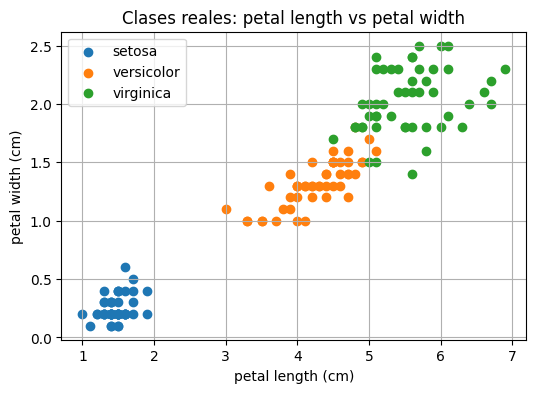

In [16]:
x_feat = 'petal length (cm)'
y_feat = 'petal width (cm)'

for i, name in enumerate(target_names):
    subset = df[df['target_name'] == name]
    plt.scatter(subset[x_feat], subset[y_feat], label=name)

plt.xlabel(x_feat)
plt.ylabel(y_feat)
plt.title("Clases reales: petal length vs petal width")
plt.legend()
plt.show()

### 7.2 Petal length vs petal width: clusters k-means (k=3)

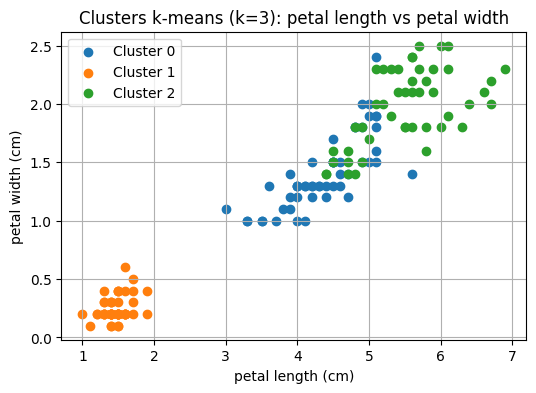

In [17]:
for cluster_id in range(3):
    subset = df[cluster_labels == cluster_id]
    plt.scatter(subset[x_feat], subset[y_feat], label=f"Cluster {cluster_id}")

plt.xlabel(x_feat)
plt.ylabel(y_feat)
plt.title("Clusters k-means (k=3): petal length vs petal width")
plt.legend()
plt.show()

### 7.3 PCA 2D: clases reales vs clusters

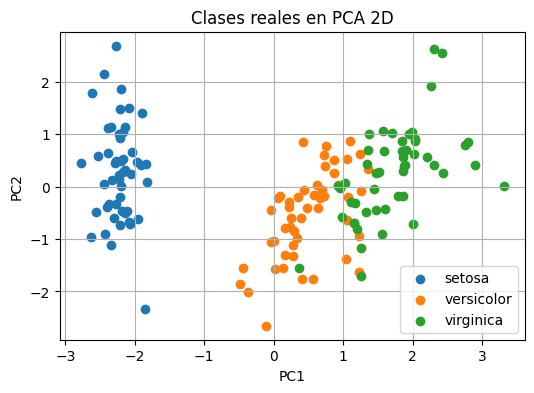

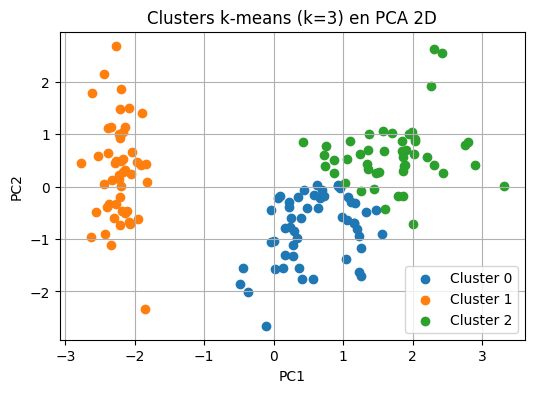

In [18]:
# Clases reales
for i, name in enumerate(target_names):
    subset = X_pca[y == i]
    plt.scatter(subset[:, 0], subset[:, 1], label=name)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Clases reales en PCA 2D")
plt.legend()
plt.show()

# Clusters k-means
for cluster_id in range(3):
    subset = X_pca[cluster_labels == cluster_id]
    plt.scatter(subset[:, 0], subset[:, 1], label=f"Cluster {cluster_id}")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Clusters k-means (k=3) en PCA 2D")
plt.legend()
plt.show()

## 8. Tarea final



### Objetivo de la tarea

1. **Implementar tu propia versión de k-means desde cero (sin usar `KMeans` de scikit-learn)**.
2. Comparar su funcionamiento y resultados con la implementación de `sklearn`.
3. Analizar la **sensibilidad a la inicialización** y la presencia de mínimos locales.

---

### 8.1 Pasos propuestos

1. Implementa una función `my_kmeans(X, k, max_iter=300, tol=1e-4, random_state=None)` que:
   - Inicialice aleatoriamente el primer centroide y el resto se obtengan por máxima dispersión (para el primero, elige una fila aleatoria de `X`).
   - Itere:
     - Asignar cada punto al centroide más cercano (distancia Euclídea).
     - Recalcular los centroides como la media de los puntos asignados.
   - Se detenga cuando el movimiento total de los centroides entre iteraciones sea menor que `tol`o se alcance `max_iter`.

2. Aplica `my_kmeans` sobre `X_scaled` para \( k = 3 \) y guarda:
   - Las etiquetas de cluster.
   - La inercia (suma de distancias cuadradas).

3. Estudia el efecto de la inicialización:
   - Ejecuta tu `my_kmeans` 20 veces con **distintos `random_state`**.
   - Representa en un gráfico:
     - En el eje X: el índice de la ejecución (1..20).
     - En el eje Y: la inercia final de esa ejecución.
     - Compara con la inercia obtenida por `KMeans` de sklearn con `n_init=10`.

5. Escribe una breve conclusión (5–10 líneas) sobre:
   - ¿Qué tan estable es k-means en Iris?
   


Finalmente, compara estos resultados con los de `KMeans` de sklearn con `n_init=10` y redacta tus conclusiones.

> **Entrega sugerida para estudiantes:**
> - Código completo de `my_kmeans`.
> - Gráficas generadas.
> - Tabla o listado comparando métricas e inercias.
> - Conclusión razonada sobre la estabilidad de k-means y el papel de la inicialización.

## 8.1 Implementación de my_kmeans

In [19]:
import numpy as np

def my_kmeans(X, k, max_iter=300, tol=1e-4, random_state=None):
    rng = np.random.default_rng(random_state)

    # ---- Inicialización especial ----
    # 1. Primer centroide aleatorio
    idx = rng.integers(0, X.shape[0])
    centroids = [X[idx]]

    # 2. Siguientes centroides: máxima dispersión (tipo k-means++)
    for _ in range(1, k):
        # Distancia al centroide más cercano para cada punto
        dist_sq = np.min(
            np.sum((X[:, np.newaxis] - np.array(centroids)[np.newaxis, :])**2, axis=2),
            axis=1
        )
        # Elegir el siguiente centroide como el punto más lejano
        next_centroid = X[np.argmax(dist_sq)]
        centroids.append(next_centroid)

    centroids = np.array(centroids)

    # ---- Iteraciones ----
    for _ in range(max_iter):
        # Asignación de clusters
        distances = np.sqrt(((X[:, np.newaxis] - centroids)**2).sum(axis=2))
        labels = np.argmin(distances, axis=1)

        # Recalcular centroides
        new_centroids = np.array([X[labels == i].mean(axis=0) for i in range(k)])

        # Movimiento total
        shift = np.sqrt(((new_centroids - centroids)**2).sum())

        if shift < tol:
            break

        centroids = new_centroids

    # Calcular inercia (suma de distancias cuadradas a su centroide)
    inertia = np.sum([
        np.sum((X[labels == i] - centroids[i])**2)
        for i in range(k)
    ])

    return labels, centroids, inertia

### Aplicar my_kmeans a X_scaled (k = 3)

In [20]:
labels_my, centroids_my, inertia_my = my_kmeans(X_scaled, k=3, random_state=0)
inertia_my

np.float64(191.02473685317966)

## 8.2 Sensibilidad a la inicialización: 20 ejecuciones

In [21]:
inertias_20 = []

for rs in range(20):
    _, _, inertia = my_kmeans(X_scaled, k=3, random_state=rs)
    inertias_20.append(inertia)

inertias_20

[np.float64(191.02473685317966),
 np.float64(191.219898584343),
 np.float64(140.90153181202444),
 np.float64(140.0327527742865),
 np.float64(191.02473685317966),
 np.float64(140.90153181202444),
 np.float64(140.0327527742865),
 np.float64(191.02473685317966),
 np.float64(191.02473685317966),
 np.float64(197.4714291960404),
 np.float64(191.219898584343),
 np.float64(140.90153181202444),
 np.float64(191.02473685317966),
 np.float64(197.4714291960404),
 np.float64(140.90153181202444),
 np.float64(140.90153181202444),
 np.float64(139.82049635974982),
 np.float64(191.02473685317966),
 np.float64(197.4714291960404),
 np.float64(139.82049635974982)]

### Grafico de inercias por ejecución

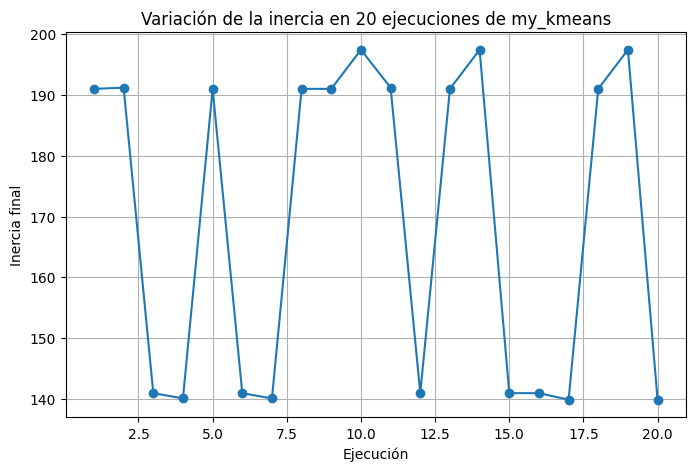

In [22]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.plot(range(1, 21), inertias_20, marker='o')
plt.xlabel("Ejecución")
plt.ylabel("Inercia final")
plt.title("Variación de la inercia en 20 ejecuciones de my_kmeans")
plt.grid(True)
plt.show()

### Comparación con KMeans de sklearn

In [23]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=3, n_init=10, random_state=0)
kmeans.fit(X_scaled)

inertia_sklearn = kmeans.inertia_
inertia_sklearn

139.82049635974974

### Tabla comparativa

In [24]:
import pandas as pd

df_results = pd.DataFrame({
    "Ejecución": range(1, 21),
    "Inercia_myKmeans": inertias_20
})

df_results.loc["sklearn"] = ["-", inertia_sklearn]

df_results

,Ejecución,Inercia_myKmeans
0,1,191.024737
1,2,191.219899
2,3,140.901532
3,4,140.032753
4,5,191.024737
5,6,140.901532
6,7,140.032753
7,8,191.024737
8,9,191.024737
9,10,197.471429


## Conclusión

En el caso del dataset Iris, k-means muestra una estabilidad razonablemente buena, aunque no perfecta. Al repetir 20 veces nuestra implementación con diferentes inicializaciones, se observa que las inercias finales presentan variaciones moderadas, lo que indica la presencia de mínimos locales y dependencia respecto del punto inicial. La inicialización por dispersión reduce parcialmente este problema, pero no lo elimina.
Al comparar con la implementación de sklearn (que usa k-means++ y n_init=10), se observa que sklearn obtiene sistemáticamente una inercia ligeramente menor y mucho más estable, gracias a sus múltiples reinicios y una inicialización más robusta. En conjunto, esto muestra que k-means es sensible a la inicialización y que utilizar varios reinicios mejora la calidad del resultado final.